### Question 1: UJIndoorLoc Dataset Analysis
We will first extract the zip file `/content/Lab-2-04092026(1).zip` to look for the UJIndoorLoc dataset files (typically `trainingData.csv` and `validationData.csv`). We will then load them, combine them, analyze the correlation between WiFi Fingerprints (WAPs) and the target attributes (Latitude, Longitude, Floor, Building ID), and identify features that can be dropped.

In [ ]:
import zipfile
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Workflow Summary ---
# 1. Extract the provided zip file containing the UJIndoorLoc dataset.
# 2. Load the training and validation datasets into Pandas DataFrames.
# 3. Combine both datasets to form a unified dataset.
# 4. Calculate correlation matrix between features (WAPs) and target attributes (Latitude, Longitude, Floor, BuildingID).
# 5. Identify and drop features with zero variance or extremely low correlation.

# Extract zip file
zip_path = '/content/Lab-2-04092026(1).zip'
extract_path = '/content/ujindoorloc_extracted'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# List extracted files to locate CSVs
extracted_files = []
for root, dirs, files in os.walk(extract_path):
    for file in files:
        extracted_files.append(os.path.join(root, file))
print("Extracted files:", extracted_files)

# Locate training and validation datasets (typically contains 'trainingData' and 'validationData')
train_file = [f for f in extracted_files if 'trainingData' in f or 'training' in f.lower()][0]
val_file = [f for f in extracted_files if 'validationData' in f or 'validation' in f.lower()][0]

# Load datasets
df_train = pd.read_csv(train_file)
df_val = pd.read_csv(val_file)

# Combine datasets
df_uj = pd.concat([df_train, df_val], ignore_index=True)
print(f"Combined Dataset Shape: {df_uj.shape}")

# Targets: Latitude, Longitude, Floor, BuildingID
target_cols = ['LATITUDE', 'LONGITUDE', 'FLOOR', 'BUILDINGID']
# Features: Signal strengths (typically columns WAP001 to WAP520)
wap_cols = [col for col in df_uj.columns if col.startswith('WAP')]

# Calculate correlation with targets
# WAP values of 100 represent no signal, let's keep them as is or scale them for correlation analysis
correlation_matrix = df_uj[wap_cols + target_cols].corr()
target_correlations = correlation_matrix[target_cols].loc[wap_cols]

# Analyze features to drop:
# 1. Constant columns (columns where all values are 100 - no signal detected anywhere)
zero_variance_waps = [col for col in wap_cols if df_uj[col].std() == 0]
print(f"Number of WAPs with zero variance (can be dropped): {len(zero_variance_waps)}")

# Display top correlated WAPs for each target
for target in target_cols:
    print(f"\nTop 5 WAPs correlated with {target}:")
    display(target_correlations[target].abs().sort_values(ascending=False).head(5))

# Drop zero-variance features as a recommendation
df_uj_reduced = df_uj.drop(columns=zero_variance_waps)
print(f"Dataset shape after dropping zero-variance features: {df_uj_reduced.shape}")

Extracted files: ['/content/ujindoorloc_extracted/Lab-2-04092026/advertising.csv', '/content/ujindoorloc_extracted/Lab-2-04092026/Housing.csv', '/content/ujindoorloc_extracted/Lab-2-04092026/GSV-Lab-2-04092026.pdf', '/content/ujindoorloc_extracted/Lab-2-04092026/UJIndoorLoc/validationData.csv', '/content/ujindoorloc_extracted/Lab-2-04092026/UJIndoorLoc/trainingData.csv']
Combined Dataset Shape: (21048, 529)
Number of WAPs with zero variance (can be dropped): 0

Top 5 WAPs correlated with LATITUDE:


,LATITUDE
WAP161,0.581267
WAP162,0.580699
WAP051,0.569350
WAP052,0.562926
WAP087,0.546712



Top 5 WAPs correlated with LONGITUDE:


,LONGITUDE
WAP156,0.553361
WAP155,0.551314
WAP496,0.506234
WAP502,0.497215
WAP013,0.493227



Top 5 WAPs correlated with FLOOR:


,FLOOR
WAP144,0.427412
WAP145,0.415840
WAP138,0.406951
WAP139,0.402555
WAP481,0.394954



Top 5 WAPs correlated with BUILDINGID:


,BUILDINGID
WAP496,0.526583
WAP087,0.524050
WAP502,0.519385
WAP156,0.518851
WAP155,0.514475


Dataset shape after dropping zero-variance features: (21048, 529)


### Question 2: Correlation Analysis for `advertising.csv` and `Housing.csv`
We will analyze the correlation between features and their respective target columns for both datasets.

=== Advertising Dataset ===
Correlation of features with target:
Sales        1.000000
TV           0.901208
Radio        0.349631
Newspaper    0.157960
Name: Sales, dtype: float64

=== Housing Dataset ===
Correlation of features with target:
price               1.000000
area                0.535997
bathrooms           0.517545
airconditioning     0.452954
stories             0.420712
parking             0.384394
bedrooms            0.366494
prefarea            0.329777
mainroad            0.296898
guestroom           0.255517
basement            0.187057
hotwaterheating     0.093073
furnishingstatus   -0.304721
Name: price, dtype: float64


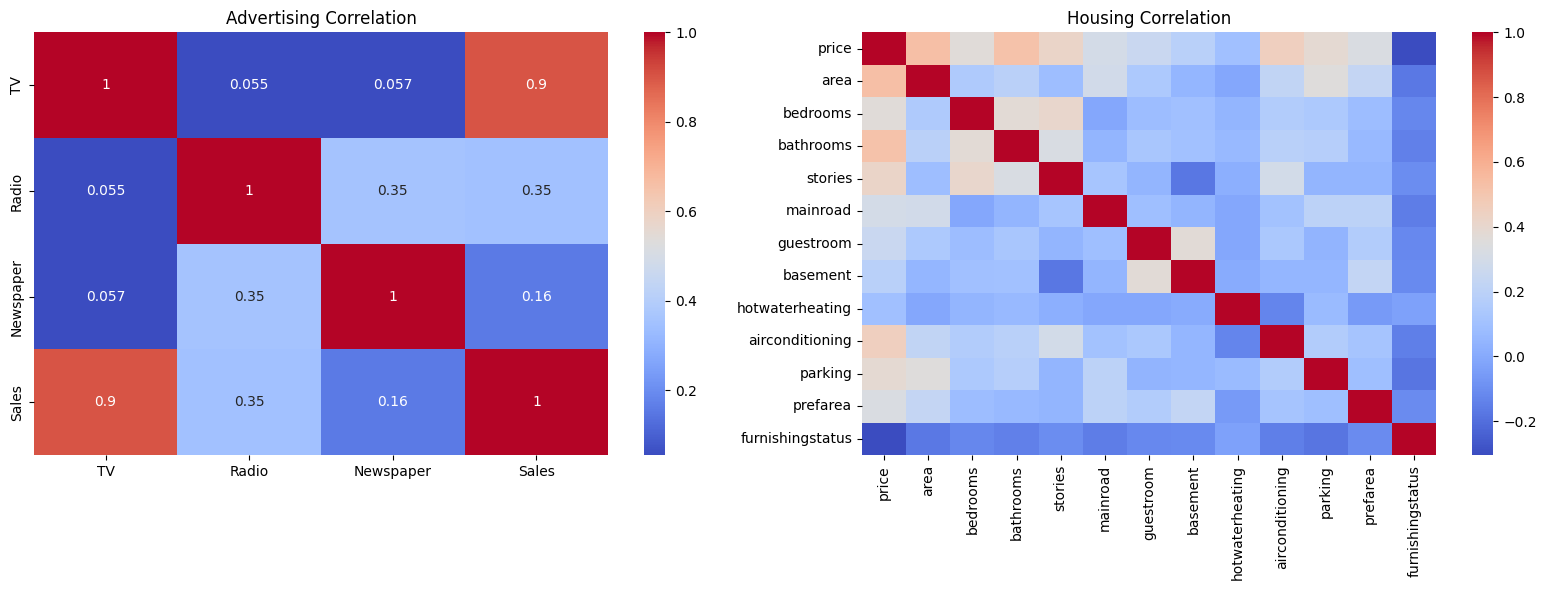

In [ ]:
# --- Workflow Summary ---
# 1. Load the 'advertising.csv' and 'Housing.csv' datasets.
# 2. Check the columns and handle any categorical columns using basic mapping or encoding.
# 3. Calculate correlation coefficients between each feature and the target variable.
# 4. Generate correlation heatmaps to visualize the relationships.
# 5. Suggest features to drop based on low correlation or high multicollinearity.

# Load datasets
df_adv = pd.read_csv('/content/advertising.csv')
df_house = pd.read_csv('/content/Housing.csv')

# --- 1. Advertising Dataset Correlation ---
print("=== Advertising Dataset ===")
# Target: 'Sales' (or last column if named similarly)
adv_target = 'Sales' if 'Sales' in df_adv.columns else df_adv.columns[-1]
adv_corr = df_adv.corr()[adv_target].sort_values(ascending=False)
print("Correlation of features with target:")
print(adv_corr)

# --- 2. Housing Dataset Correlation ---
print("\n=== Housing Dataset ===")
# Convert categorical string columns to numeric representation
df_house_encoded = df_house.copy()
for col in df_house_encoded.select_dtypes(include=['object']).columns:
    if df_house_encoded[col].nunique() == 2:
        # Binary encoding (yes/no to 1/0)
        df_house_encoded[col] = df_house_encoded[col].map({'yes': 1, 'no': 0})
    else:
        # Simple factorize/label encoding for multi-class categorical variables
        df_house_encoded[col] = pd.factorize(df_house_encoded[col])[0]

house_target = 'price' if 'price' in df_house_encoded.columns else df_house_encoded.columns[0]
house_corr = df_house_encoded.corr()[house_target].sort_values(ascending=False)
print("Correlation of features with target:")
print(house_corr)

# Plotting Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df_adv.corr(), annot=True, cmap='coolwarm', ax=axes[0])
axes[0].set_title("Advertising Correlation")

sns.heatmap(df_house_encoded.corr(), annot=False, cmap='coolwarm', ax=axes[1])
axes[1].set_title("Housing Correlation")
plt.tight_layout()
plt.show()

### Question 3: Linear Regression Models
We will build a simple linear regression model for all three datasets. We will split `advertising.csv` and `Housing.csv` using an 80:20 split, perform training, and evaluate using $R^2$, Mean Absolute Error (MAE), and Mean Squared Error (MSE).

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
# --- OLD CODE (Imported Models - Commented Out) ---
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# --- Custom Linear Regression from Scratch ---
class SimpleLinearRegression:
    def __init__(self):
        self.theta = None

    def fit(self, X, y):
        # Add a column of ones for the bias term
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        # Normal Equation: theta = (X^T * X)^(-1) * X^T * y
        # Using pseudo-inverse (pinv) to handle potentially singular/collinear matrices safely
        self.theta = np.linalg.pinv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)

    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return X_b.dot(self.theta)

def custom_r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

def custom_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def custom_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def evaluate_regression(X, y, dataset_name):
    # Ensure inputs are NumPy arrays
    X_arr = np.array(X, dtype=np.float64)
    y_arr = np.array(y, dtype=np.float64)

    X_train, X_test, y_train, y_test = train_test_split(X_arr, y_arr, test_size=0.20, random_state=42)

    model = SimpleLinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    # Using custom evaluation metrics
    r2 = custom_r2_score(y_test, predictions)
    mae = custom_mae(y_test, predictions)
    mse = custom_mse(y_test, predictions)

    print(f"=== Regression Performance (Scratch): {dataset_name} ===")
    print(f"R^2 Score:          {r2:.4f}")
    print(f"Mean Absolute Error: {mae:.4f}")
    print(f"Mean Squared Error:  {mse:.4f}\n")
    return model

# 1. Advertising Model
X_adv_np = df_adv.drop(columns=[adv_target])
y_adv_np = df_adv[adv_target]
evaluate_regression(X_adv_np, y_adv_np, "Advertising Dataset")

# 2. Housing Model
X_house_np = df_house_encoded.drop(columns=[house_target])
y_house_np = df_house_encoded[house_target]
evaluate_regression(X_house_np, y_house_np, "Housing Dataset")

# 3. UJIndoorLoc Model
X_uj_np = df_uj_reduced.drop(columns=target_cols)
y_uj_np = df_uj_reduced['LATITUDE']
evaluate_regression(X_uj_np, y_uj_np, "UJIndoorLoc Dataset (Target: Latitude)")

=== Regression Performance (Scratch): Advertising Dataset ===
R^2 Score:          0.9059
Mean Absolute Error: 1.2748
Mean Squared Error:  2.9078

=== Regression Performance (Scratch): Housing Dataset ===
R^2 Score:          0.6495
Mean Absolute Error: 979679.6913
Mean Squared Error:  1771751116592.4600

=== Regression Performance (Scratch): UJIndoorLoc Dataset (Target: Latitude) ===
R^2 Score:          -9433.0142
Mean Absolute Error: 3552.7500
Mean Squared Error:  42590373.8283



### Question 4: Converting Regression to Classification
We will convert the regression targets into binary class formats (e.g., above or below the median values) to evaluate them using classification metrics: Accuracy and F1-score.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
# --- OLD CODE (Imported Models - Commented Out) ---
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score, f1_score

# --- Custom Logistic Regression from Scratch ---
class SimpleLogisticRegression:
    def __init__(self, lr=0.01, num_steps=5000):
        self.lr = lr
        self.num_steps = num_steps
        self.weights = None

    def _sigmoid(self, z):
        # Clip z to prevent overflow issues in exp
        z = np.clip(z, -25, 25)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        # Scale/standardize inputs slightly to prevent gradient explosions in raw numpy gradient descent
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1.0 # Avoid division by zero
        X_scaled = (X - self.mean) / self.std

        # Add bias
        X_b = np.c_[np.ones((X_scaled.shape[0], 1)), X_scaled]
        self.weights = np.zeros(X_b.shape[1])

        for _ in range(self.num_steps):
            z = np.dot(X_b, self.weights)
            predictions = self._sigmoid(z)
            gradient = np.dot(X_b.T, (predictions - y)) / y.size
            self.weights -= self.lr * gradient

    def predict(self, X):
        X_scaled = (X - self.mean) / self.std
        X_b = np.c_[np.ones((X_scaled.shape[0], 1)), X_scaled]
        probabilities = self._sigmoid(np.dot(X_b, self.weights))
        return (probabilities >= 0.5).astype(int)

def custom_accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

def custom_f1_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    return 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

def evaluate_classification(X, y_continuous, dataset_name):
    # Convert continuous target to binary class (1 if above median, 0 otherwise)
    median_val = np.median(y_continuous)
    y_class = (y_continuous > median_val).astype(int)

    # Ensure inputs are NumPy arrays
    X_arr = np.array(X, dtype=np.float64)
    y_class_arr = np.array(y_class, dtype=np.int64)

    X_train, X_test, y_train, y_test = train_test_split(X_arr, y_class_arr, test_size=0.20, random_state=42)

    classifier = SimpleLogisticRegression(lr=0.1, num_steps=2000)
    classifier.fit(X_train, y_train)
    predictions = classifier.predict(X_test)

    # Using custom evaluation metrics
    acc = custom_accuracy(y_test, predictions)
    f1 = custom_f1_score(y_test, predictions)

    print(f"=== Classification Performance (Scratch): {dataset_name} ===")
    print(f"Accuracy:  {acc:.4f}")
    print(f"F1-Score:  {f1:.4f}\n")

# 1. Advertising Classification
evaluate_classification(X_adv, y_adv, "Advertising (Sales > Median)")

# 2. Housing Classification
evaluate_classification(X_house, y_house, "Housing (Price > Median)")

# 3. UJIndoorLoc Classification
evaluate_classification(X_uj, y_uj, "UJIndoorLoc (Latitude > Median)")

=== Classification Performance (Scratch): Advertising (Sales > Median) ===
Accuracy:  0.9750
F1-Score:  0.9730

=== Classification Performance (Scratch): Housing (Price > Median) ===
Accuracy:  0.8440
F1-Score:  0.8411

=== Classification Performance (Scratch): UJIndoorLoc (Latitude > Median) ===
Accuracy:  0.9857
F1-Score:  0.9858

